In [2]:
import tensorflow as tf
from tensorflow.keras.layers import (
    Conv2D,
    Input,
    Dense,
    MaxPool2D,
    BatchNormalization,
    Flatten,
    GlobalAvgPool2D
)
import numpy as np
import matplotlib.pyplot as plt

print(tf.__version__)

2.21.0


In [3]:
def load_data():
    return tf.keras.datasets.mnist.load_data()

In [4]:
(x_train,y_train),(x_test,y_test) = load_data()

In [5]:
print(x_train.shape,y_train.shape,x_test.shape,y_test.shape)

(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


In [6]:
def display_examples(examples,labels):
    plt.figure(figsize=(10,10))
    for i in range(25):
        idx = np.random.randint(0,examples.shape[0]-1)
        img = examples[idx]
        label = labels[idx]
        plt.subplot(5,5,i+1)
        plt.title("label: " + str(label))
        plt.tight_layout()
        plt.imshow(img)
    plt.show()

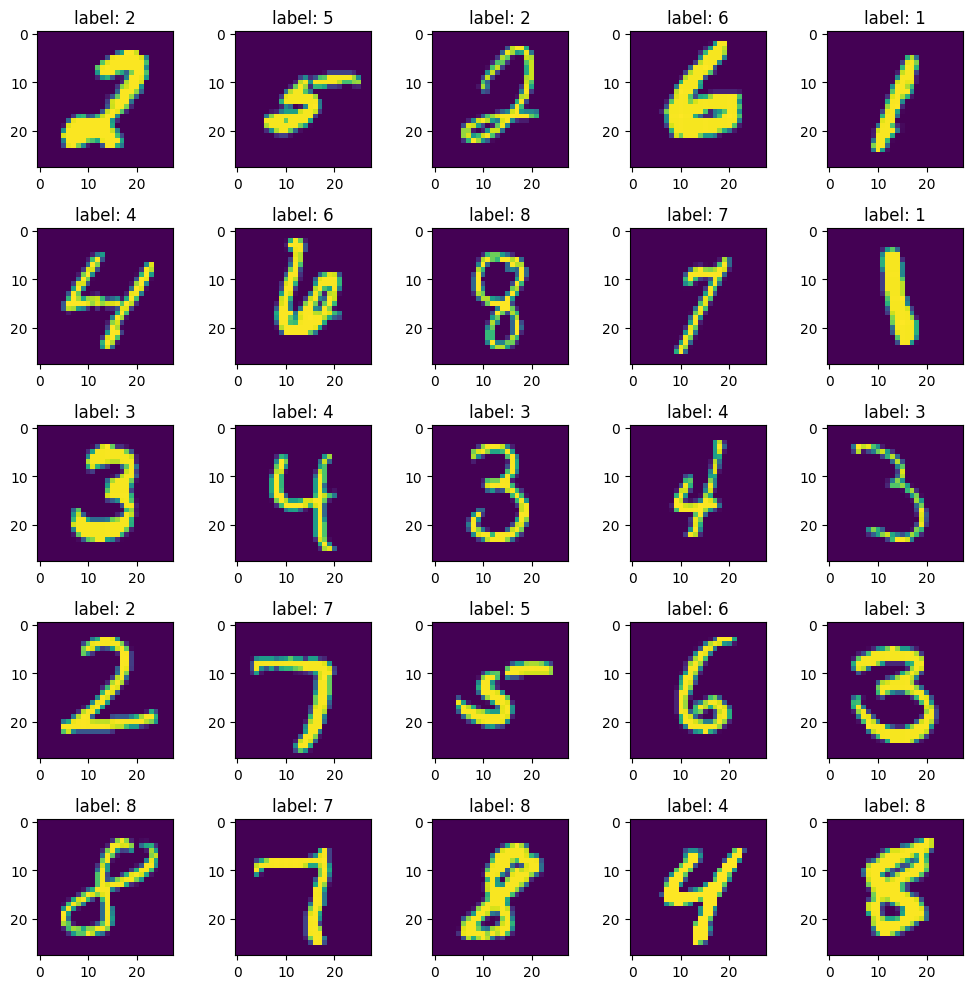

In [7]:
display_examples(x_train,y_train)

## how to build a neural network?
```
tensorflow.keras.Sequential | functional approach: function that returns a model | tensorflow.keras.Model: inherit from this class
```
Conv2D(32, (3,3), activation='relu')
- the model learn 32 deferent filters, each filter looks for a patterns in the image.
- (3,3) kernel size,kernel is a small matrix that moves across the image.
- activation-'relu' stand for Rectified Linear Unit. negative values become 0, positive values remain unchaged.
-ReLU introduces nonlinearity, allowing the model to learn more complex patterns.


ANN

In [ ]:
seq_model = tf.keras.Sequential([
    Input(shape=(28, 28, 1)), # defines the shape of the images ,1 -> Grayscale, 3 -> RGB(red,green,blue) in general it stand for image channel
    Conv2D(32, (3,3), activation='relu'), # confolutional layer that learn to detect patterns in images.
    MaxPool2D(), # Reduce and normalize features and changing the the shape to let the model recognize more complexd pattern
    BatchNormalization(), # Reduce and normalize features ,make neural network training more stable ad somtimes faster.

    Conv2D(128,(3,3),activation="relu"),
    MaxPool2D(),# Reduce and normalize features and changing the the shape to let the model recognize more complexd pattern 
    BatchNormalization(), # Reduce and normalize features ,make neural network training more stable ad somtimes faster.

    GlobalAvgPool2D(), # Convert feature maps into a vector
    Dense(64,activation="relu"), # combine the features from the privews layer. 128 -> 64
    Dense(10,activation="softmax"), # make prediction using Dense layers. converts the 10 output score into probabilities that add up to 1.as_integer_ratio
])

In [9]:
model.summary() # summarys the model that we have

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 13, 13, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 128)    │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 5, 5, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,858 (183.04 KB)

 Trainable params: 46,538 (181.79 KB)

 Non-trainable params: 320 (1.25 KB)

```Pixel normalization``` || ```Pixel rescaling```

Why devide by 255?
- In a typical 8-bit grayscale image, each pixel has a value between 0 and 255.
    - 0 -> Black
    - 128 -> Gray
    - 255 -> White

In [10]:
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

In [11]:
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28)
(10000, 28, 28)


change the ```array shape``` because convolutional layers process image channels,
Even though your ```grayscale``` image contains only one channel, you still need to represent it explicitly so that ```Conv2D``` understands the input.

In [12]:
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

In [13]:
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


optimizer = {"adam", "ada", "adadelta", "adagrad", "adamax", "ftrl", "nadam", "optimizer", "rmsprop", "sgd"}
loss = {"crossentropy","categorical_","",""}
metrics = {"","",""}

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy", # or use ts.keras.utils.to_categorical
    metrics=["accuracy"]
)

model.fit(x_train, y_train, batch_size=64, epochs=3, validation_split=0.2)

Epoch 1/3
750/750 ━━━━━━━━━━━━━━━━━━━━ 63s 80ms/step - accuracy: 0.9863 - loss: 0.0431 - val_accuracy: 0.9645 - val_loss: 0.1214
Epoch 2/3
750/750 ━━━━━━━━━━━━━━━━━━━━ 61s 81ms/step - accuracy: 0.9892 - loss: 0.0340 - val_accuracy: 0.9594 - val_loss: 0.1351
Epoch 3/3
750/750 ━━━━━━━━━━━━━━━━━━━━ 64s 86ms/step - accuracy: 0.9910 - loss: 0.0268 - val_accuracy: 0.9762 - val_loss: 0.0774


In [ ]:
model.evaluate(x_test, y_test, batch_size=64)

157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9751 - loss: 0.0744


[0.07443159073591232, 0.9750999808311462]

In [28]:
def functional_model():
    my_input = Input(shape=(28, 28, 1)) 
    x = Conv2D(32, (3,3), activation='relu')(my_input)
    x = Conv2D(64,(3,3),activation='relu')(x)
    x = MaxPool2D()(x)
    x = BatchNormalization()(x)

    x = Conv2D(128,(3,3),activation="relu")(x)
    x = MaxPool2D()(x)
    x = BatchNormalization()(x)

    x = GlobalAvgPool2D()(x)
    x = Dense(64,activation="relu")(x)
    x = Dense(10,activation="softmax")(x)
    return tf.keras.Model(inputs=my_input,outputs=x)

In [29]:
model = functional_model()
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 10, 10, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 5, 5, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,346 (399.79 KB)

 Trainable params: 101,962 (398.29 KB)

 Non-trainable params: 384 (1.50 KB)